USO EMBEDDINGS OPEN AI PER RICERCA SEMANTICA

Fino ad ora abbiamo trattato le parole come stringhe di test.
Per un computer le parole sono solo simboli vuoti.
l'API di openai trasforma il linguaggio in geometria operativa, passeremo da cercare le lettere a cercare il significato.

Gli Embeddings permettono di cercare testi per affinità di significato, anche quando usano parole diverse.
La ricerca semantica può collegare concetti come 'restituire' oppure 'gusto' e 'difettoso'. E' uno degli impieghi degli embeddings

- Cosine Similarity: la metrica matematica della vicinanza semantica
- Semantic Search vs Keyword Search: superare i limiti del matching letterale
- Clustering e Visualizzazione: organizzare i dati con t-SNE e UMAP

Come si misura il peso di un idea?
La Geometria del Significato
Cosine Similarity e Spazi Vettoriali.
Gli embeddings trasformano stringhe di testo in vettori densi in uno spazio ad altissima dimensionalità. In questo spazio, il significato non è definito da lettere che compongono la parola, ma dalla posizione relativa dei vettori.
Se due frasi parlano lo stesso concetto i loro vettori puntano alla stessa direzione.
Per determinare quanto due concetti siano simili, non misuriamo la distanza euclidea tra i punti, ma l'angolo compreso tra i loro vettori: questa è la base della similutidine cosina.

Come facciamo a dire quanto due freccie siano simili all'interno di questo spazio?

Matematica dei Vettori
Prodotto scalare e normalizzazione
- Vettori Densamento Popolati: a differenza delle matrici sparce (TF-IDF), gli embeddings di OpenAI (es. text-embedding-3-small') usano 1536 dimensioni per catturare sfumature semantiche
- Prodotto Scalare: operazione che moltiplica i componenti corrispondenti di due vettori. Se i vettori sono normalizzati il risultato è direttamente il coseno dell'angolo.
- Indipendenza dalla Lunghezza: la similitudine cosina si focalizza sull'orientamento del vettore, rendendo il confronto robusto anche tra documenti di lunghezze differenti.
- Il valore della similitudine oscilla tra -1 (opposti) e 1 (identici), dove 0 indica ortogonalità semantica totale.

Le API moderne rendono questi calcolo quasi immediati

Efficienza Computazionale
Normalizzazione L2
OpenAI restituisce vettori già normalizzati (con norma unitaria), questo significa che la loro forza è già bilanciato, il che permette di calcolare la similitudine con un semplice prodotto scalare (dot product) senza divisioni aggiuntive. E' un efficienza enorme quando dobbiamo confrontare una query con migliaia di documenti in un database.
In scenari di batch, è possibile calcolare la similitudine tra una query e migliaia di documenti simultaneamente tramite moltiplicazione di matrici NumPy.
Le API moderne permettono di ridurre le dimensioni (es. a 512 o 256) tramite tecniche di 'Matryoshka Embeddings' per risparmiare memoria senza sacrificare troppa precisione.
E' come avere una foto in alta risoluzione che rimane nitida anche se riduciamo il peso del file.

Analiziamo l'operazione che sta alla base di questo processo
Analisi del Prodotto Scalare
Il calcolo della similitudine cosina è l'operazione fondamentale dietro ogni database vettoriale moderno.
Essa rappresenta la proiezione di un'intenzione (query) su una conoscenza archiviata (documento) all'interno di una varietà ipersferica.

Ogni calcolo è un calcolo in più verso la comprensione automatica del linguaggio.

La ricerca tradizionale (keyword Searach) si basa su indici invertiti e operazioni come SQL 'LIKE'. Se l'utente cerca 'felino', il sistema fallisce se nel database è presente solo la parola 'gatto'.
E' come cercare tra i titoli di un libro, senza capirne il significato.
La ricerca semantica utilizza gli embeddings per mappare entrambi i termini in zone vicine dello spazio latente, permettendo al sistema di 'capire' la relazione tra i concetti.
Il sistema non cerca più lettere, cerca l'intento.

Ma come gestisce il sistema le parole che hanno più significati?
Qui entra in gioco il potere del contesto.
il Transformer non crea un embedding statico per ogni parola, ma lo medella con ciò che ha interno. Questo modelli transformer creano embeddings contestuali che distinguono 'pesca' (frutto) da 'pesca' (sport) in base alle parole circostanti.
Gli embeddings multilingua mappano frasi in lingue diverse ma con lo stesso significato in punti simili dello spazio.
La ricerca semantica trasforma il problema del recupero da un confronto di stringhe a una ricerca di vicinato in uno spazio metrico.

Questa capacità di disambiguazione ciò che rende gli embeddings di open ai, superiori ai vecchi metodi.
Mappiamo relazioni silenziose che un tempo richiedevano dizionari infiniti di sininomi creati a mano.

Ma non è tutto oro ciò che luccica
Ci sono ancora dei limiti da considerare.
La ricerca semnatica è potente ma a volte manca di precisione chirurgica.
La ricerca semantica eccelle nel trovare concetti, ma può essere meno precisa della keyword search per codici identificativi, numeri di serie o termini tecnici rari.
Le pipeline professionali combinano punteggi vettoriali e BM25 (keyword) per ottenere il meglio da entrambi i mondi. Uniamo la ricerca semantica alla vecchia ricerca per parole chiave.
Non è necessario definire sinonimi manualmente: il modello ha già appreso queste relazioni durante il pre-addestramento su scala globale (zero-shot retrieval).

Come questi vettori ci aiutano a capire quanto è denso il nostro sapere.
Utilizzare gli embeddings ci permette di calcolare la densità di informazione del nostro database, identificando aree scoperte o ridondanze.
La query agisce come una sonda che campiona la distribuzione di probabilità del sapere archiviato.
Ci permette di verificare ridondanze o aree dove dobbiamo aggiungere più documenti per coprire tutti gli argomenti di cui parlano i nostri utenti.

Ma avere milioni di punti è difficile da gestire per l'occhio umano.
Se avete milioni di documenti non etichettati, il clustering è il vostro migliore amico. Il clustering ci permette di scoprire gruppi di argomenti emergenti senza supervisione umana.
Esploreremo come ridurre le 1536 dimensioni originali in solo 2 o 3 dimensioni per mappare visivamente l'universo dei nostri documenti.

Non possiamo, noi umani, vedere 1536 dimensioni.
Algoritmi di Proiezione.
T-SNE e UMAP
- Clustering K-Means: algoritmo per raggruppare i vettori in 'k' cluster basati sulla loro vicinanza ai centroidi nello spazio degli embeddings.
- t-SNE: tecnica di riduzione dimensionale non lineare ottima per visualizzare cluster locali, preservando le distanze ravvicinate. Schiaccia le 1536 dimensioni in sole 2 o 3
- UMAP: alternativa più veloce al t-SNE che preserva meglio la struttura globale dei dati e le gerarchie tra i gruppi. Schiaccia le 1536 dimensioni in sole 2 o 3

La visualizzazione permette di individuare 'outlier' semantici e di validare la qualità della categorizzazione automatica.

Le applicazioni pratiche di questa cartografia semantica sono incredibili
- Topic Discovery: identificare automaticamente di cosa parlano gli utenti di un form o in un set di ticket di assistenza raggruppandoli per somiglianza. Puoi analizzare il log di una intera settimana di chat di assistenza e scoprire che il 40% degli utenti ha problemi con il resete della password.
- Labelling assistito: assegnare etichette a interi gruppi di documenti basandosi sull'analisi del centroide del cluster, velocizzando l'annotazione dei dati. Etichettare manualmente solo 10 documenti e assegnare quella etichetta a tutti i restanti 500 documenti del gruppo.
- Search Augmentation: suggerisce argomenti correlati all'utente mostrando i documenti che appartengono allo stesso cluster semantico del risultato principale.

Stiamo passando dal lavora manuale certosino, a processi automatici massivi

La riduzione dimensionale, non è solo un trucco grafico (per rendere visibile l'invisibile all'occhio umano) ma è una trasformazione che preserva l'adiacenza topologica.
Compressione Semantica
L'intuizione dello spazio metrico.
La riduzione dimensionale è una trasformazione che cerca di mantenere l'adiacenza topologica dei concetti originali.
In uno spazio 2D, i concetti relativi alla 'tecnologia' appariranno come una nuvola distinta da quelli relativi alla 'cucina'

La ricerca si divide in due fasi
La prima fase è la preparazione dell'archivio: trasformi i documenti/frasi in vettori e conservi l'associazione fra vettore, testo e identificativo
La seconda fase avviene ad ogni ricerca: trasformi soltanto la domanda di ricerca in un vettore e lo confronti con quelli già preparati, il confronto di similarità. In questa fase i testi vengono ordinati per pertinenza rispetto alla frase di ricerca.
Gli embedding della prima fase e del testo della seconda fase, vengono caclolati da OpenAI, il confronto viene eseguito dal programma python.


Endpoint utilizzato: http://120.0.0.108:1234/v1/embeddings
Modello richiesto: text-embedding-embeddinggemma-300m-qat
Inizio generazione degli embedding per 9 frasi...
Esecuzione dell'algoritmo t-SNE per la riduzione dello spazio da alta dimensione a 2D...
Esecuzione del clustering K-Means sulle coordinate bidimensionali...
Inserimento delle etichette descrittive nel grafico...
Processo completato. Apertura della finestra del grafico.


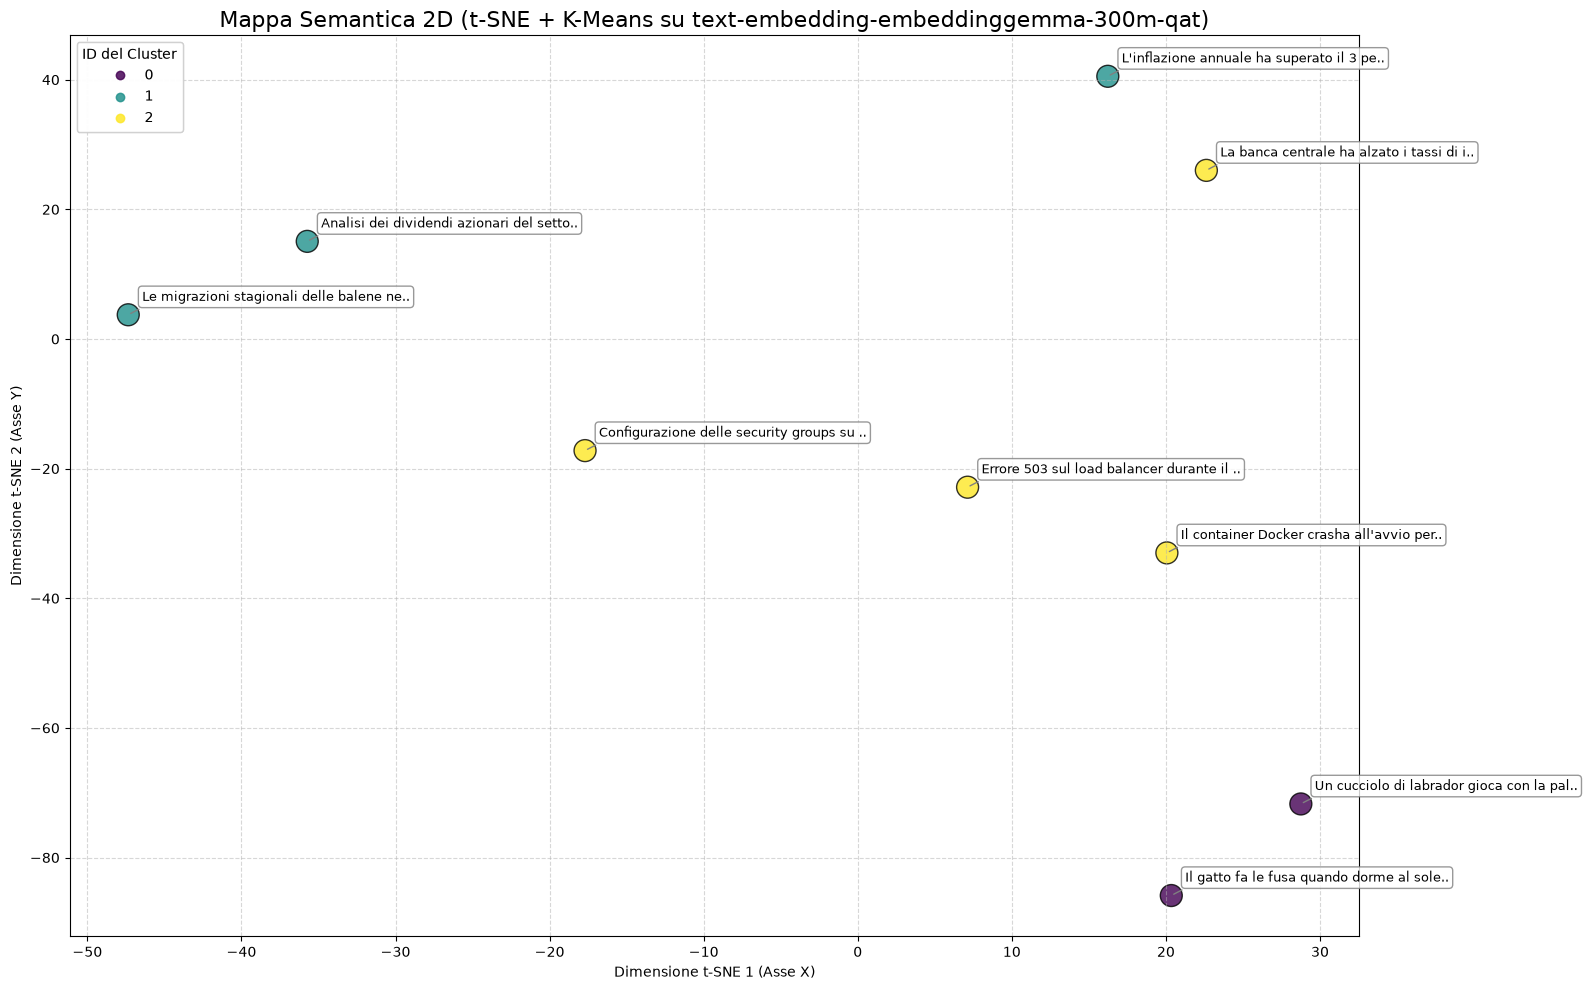

In [3]:
import torch
import requests
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from getpass import getpass

# CONFIGURAZIONE DEI PARAMETRI PER LM STUDIO
# Questo blocco definisce le coordinate per comunicare con il server locale di LM Studio.
# Il server deve essere avviato e il modello di embedding specificato deve essere caricato.
URL_BASE = "http://120.0.0.108:1234/v1/embeddings" 
MODEL_NAME = "text-embedding-embeddinggemma-300m"  # Identificativo del modello in uso
MODEL_NAME = "text-embedding-embeddinggemma-300m-qat"

# Se Require Authentication è attiva, inserisci il token di LM Studio.
# Altrimenti premi semplicemente Invio.
token = getpass("Token LM Studio, oppure Invio se non richiesto: ").strip()

headers = {}
if token:
    headers["Authorization"] = f"Bearer {token}"

print("Endpoint utilizzato:", URL_BASE)
print("Modello richiesto:", MODEL_NAME)

def get_local_embedding(text: str):
    """
    Questa funzione si occupa di trasformare una stringa di testo in un vettore numerico (embedding).
    Interagisce direttamente con l'API REST di LM Studio tramite una richiesta POST.
    """
    # Il payload contiene il testo da elaborare e il nome del modello richiesto.
    payload = {"input": text, "model": MODEL_NAME}
    try:
        # Invio della richiesta al server locale.
        response = requests.post(URL_BASE, json=payload)
        # Verifica se la richiesta è andata a buon fine (status code 200).
        response.raise_for_status()
        
        # Estrazione del vettore numerico dalla risposta JSON convertendolo in un tensore PyTorch.
        # Il formato di ritorno dell'API è solitamente una lista di numeri decimali.
        return torch.tensor(response.json()["data"][0]["embedding"], dtype=torch.float32)
    except Exception as e:
        # In caso di errore (es. server spento o modello errato), viene stampato il dettaglio.
        print(f"Errore durante il recupero dell'embedding: {e}")
        return None

# 1. DEFINIZIONE DEL DATASET
# Creiamo una lista di frasi appartenenti a tre categorie semantiche distinte:
# Tecnologia/Cloud, Natura/Animali e Finanza/Economia.
sentences = [
    # Categoria: Tecnologia e Infrastruttura
    "Errore 503 sul load balancer durante il picco di traffico.",
    "Configurazione delle security groups su AWS EC2.",
    "Il container Docker crasha all'avvio per memoria insufficiente.",
    # Categoria: Mondo Naturale
    "Il gatto fa le fusa quando dorme al sole.",
    "Le migrazioni stagionali delle balene nell'oceano.",
    "Un cucciolo di labrador gioca con la pallina.",
    # Categoria: Economia e Finanza
    "La banca centrale ha alzato i tassi di interesse.",
    "L'inflazione annuale ha superato il 3 percento.",
    "Analisi dei dividendi azionari del settore tech."
]

print(f"Inizio generazione degli embedding per {len(sentences)} frasi...")

# Generazione dei vettori per ogni frase.
# Viene eseguita una 'list comprehension' che chiama get_local_embedding per ogni elemento di sentences.
# torch.stack unisce i singoli vettori in un unico grande tensore (matrice), facilitandone la gestione.
embeddings_list = [get_local_embedding(s) for s in sentences]
embeddings_tensor = torch.stack(embeddings_list)

# Conversione dei dati da PyTorch a NumPy.
# Scikit-learn (usata dopo per t-SNE e KMeans) richiede matrici NumPy invece di tensori PyTorch.
X_high_dim = embeddings_tensor.detach().numpy()

# 2. RIDUZIONE DIMENSIONALE CON t-SNE
# Gli embedding originali hanno centinaia o migliaia di dimensioni (es. 1536 o 768).
# Per poterli visualizzare su uno schermo, dobbiamo ridurli a 2 dimensioni.
print("Esecuzione dell'algoritmo t-SNE per la riduzione dello spazio da alta dimensione a 2D...")

# t-SNE (t-distributed Stochastic Neighbor Embedding) preserva le distanze relative:
# frasi simili rimarranno vicine anche nello spazio 2D ridotto.
tsne = TSNE(
    n_components=2,     # Vogliamo ottenere coordinate (x, y)
    perplexity=3,       # Parametro che influenza il bilanciamento tra visione locale e globale (basso per pochi dati)
    random_state=42,    # Fissa il seme per ottenere lo stesso risultato a ogni esecuzione
    init='pca'
)
# fit_transform calcola la riduzione e restituisce le nuove coordinate 2D.
X_2d = tsne.fit_transform(X_high_dim)

# 3. RAGGRUPPAMENTO (CLUSTERING) CON K-MEANS
# Ora che abbiamo i punti in 2D, usiamo K-Means per identificarne i gruppi naturali.
print("Esecuzione del clustering K-Means sulle coordinate bidimensionali...")

# KMeans cercherà di dividere i dati in 3 gruppi (n_clusters=3).
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
# fit_predict assegna a ogni punto un'etichetta numerica (0, 1 o 2) che indica l'appartenenza al cluster.
cluster_labels = kmeans.fit_predict(X_2d)

# 4. CREAZIONE DEL GRAFICO (VISUALIZZAZIONE)
# Utilizziamo la libreria Matplotlib per generare un'immagine comprensibile dei cluster trovati.
plt.figure(figsize=(16, 10))

# Creazione dello scatter plot (grafico a dispersione).
# X_2d[:, 0] sono le ascisse, X_2d[:, 1] le ordinate.
# Il colore 'c' è determinato dalle etichette del cluster identificate da K-Means.
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=cluster_labels, 
    cmap='viridis',     # Schema colori per distinguere i cluster
    s=250,              # Dimensione dei punti nel grafico
    edgecolors='black', # Bordo nero per rendere i punti più definiti
    alpha=0.8           # Leggera trasparenza
)

# Inserimento delle annotazioni testuali per ogni punto sul grafico.
print("Inserimento delle etichette descrittive nel grafico...")
for i, txt in enumerate(sentences):
    # Abbreviamo il testo se supera i 40 caratteri per evitare sovrapposizioni eccessive.
    short_txt = (txt[:40] + '..') if len(txt) > 40 else txt
    
    # plt.annotate permette di scrivere del testo accanto a coordinate specifiche.
    plt.annotate(
        short_txt,
        (X_2d[i, 0], X_2d[i, 1]),   # Punto esatto del grafico a cui si riferisce il testo
        xytext=(10, 10),            # Spostamento del testo rispetto al punto (10 pixel a destra e in alto)
        textcoords='offset points', # Specifica che xytext è un offset relativo
        fontsize=9,
        # Definiamo uno stile per il riquadro del testo (sfondo bianco semitrasparente).
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8),
        # Aggiungiamo una piccola linea (freccia leggera) che collega il testo al suo punto.
        arrowprops=dict(arrowstyle="-", connectionstyle="arc3,rad=0.2", color='gray')
    )

# Configurazione finale degli elementi estetici e informativi del grafico.
plt.title(f"Mappa Semantica 2D (t-SNE + K-Means su {MODEL_NAME})", fontsize=16)
plt.xlabel("Dimensione t-SNE 1 (Asse X)")
plt.ylabel("Dimensione t-SNE 2 (Asse Y)")
plt.grid(True, linestyle='--', alpha=0.5)

# Aggiunta della legenda per identificare i cluster in base al colore.
legend = plt.legend(*scatter.legend_elements(), title="ID del Cluster", loc="best")
plt.gca().add_artist(legend)

# Ottimizzazione dello spazio tra i margini e visualizzazione a schermo.
plt.tight_layout()
print("Processo completato. Apertura della finestra del grafico.")
plt.show()